# **Cardiovascular Disease dataset**

The dataset consists of 70,000 patient records containing 11 distinct features and a binary target variable used for predictive health analytics.

Cardiovascular diseases (CVDs) are the leading cause of death globally, taking an estimated 17.9 million lives each year. Finding patterns and early indicators in patient vitals and lifestyle habits is critical for preventative medical care. Publicly available medical datasets of this scale are often limited, but this collection provides comprehensive health examination records compiled to support exploratory data analysis and predictive modeling for cardiovascular risk.

### **Content**

This dataset is composed of 70,000 real patient entries split across three main categories of input features: **objective information** (such as age, height, weight, and gender), **medical examination results** (including systolic and diastolic blood pressure, cholesterol, and glucose levels), and **subjective information** reported directly by the patient regarding lifestyle habits like smoking, alcohol consumption, and physical activity.

All dataset values were recorded at the exact moment of a clinical medical examination. The primary target variable (`cardio`) indicates the presence or absence of cardiovascular disease, making this a robust binary classification problem.

## **Statistical Modelling Application**

**Risk Factor & Odds Ratio Analysis:** We examine the associations between clinical examination metrics—such as systolic (`ap_hi`) and diastolic (`ap_lo`) blood pressure, cholesterol, and glucose tiers—and the presence of cardiovascular disease. Logistic regression and odds ratio calculations are used to quantify how elevated clinical readings and abnormal biomarkers compound individual risk profiles.

**Behavioral & Lifestyle Impact:** We analyze subjective binary predictors including smoking habits (`smoke`), alcohol consumption (`alco`), and physical activity (`active`). By stratifying patient segments across these lifestyle choices, we can isolate behavioral risk multipliers and evaluate their interaction effects alongside age and body mass index (derived from height and weight).

**Predictive Performance & Distribution Summaries:** We inspect continuous predictors such as age (measured in days) and weight by computing robust summary statistics, including medians and interquartile ranges, to mitigate the influence of physiological anomalies. Advanced machine learning architectures—ranging from tree-based ensembles (such as Random Forests and LightGBM) to deep classifiers—can then be trained and validated using cross-validation to optimize ROC-AUC and classification performance.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
from matplotlib import pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sulianova/cardiovascular-disease-dataset/cardio_train.csv


In [2]:
data = pd.read_csv('/kaggle/input/datasets/sulianova/cardiovascular-disease-dataset/cardio_train.csv', sep=';')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [3]:
data.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
data.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

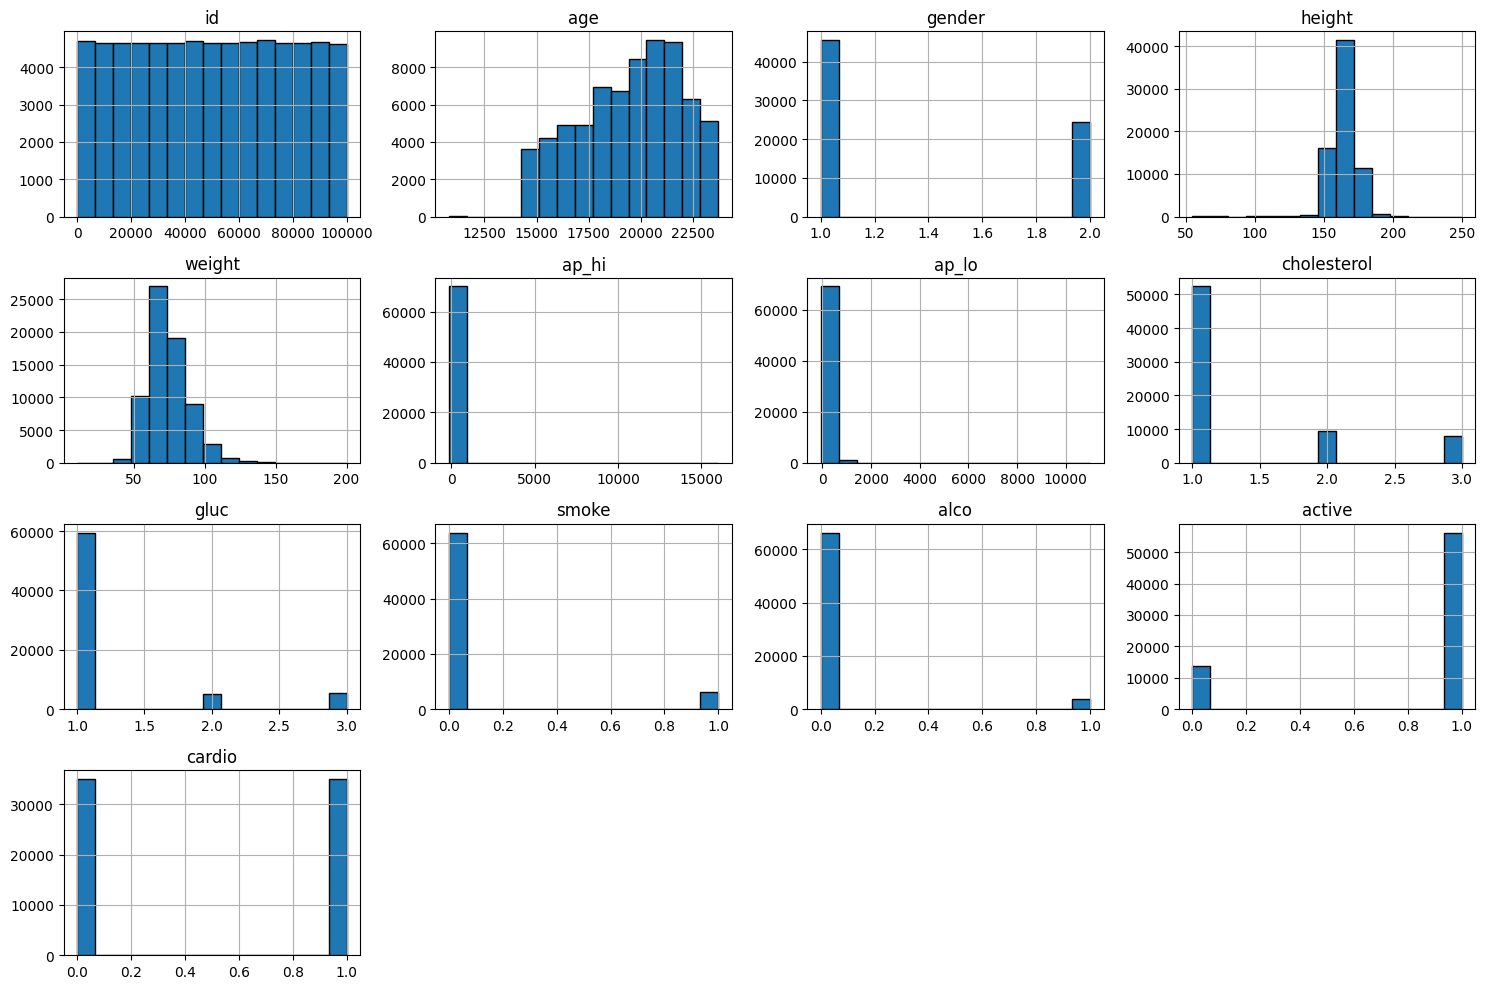

In [5]:
data.hist(bins=15, figsize=(15, 10), edgecolor='black')
plt.tight_layout()
plt.show()

## **Exploratory Data Analysis**

In [6]:
# analyse the correlation between cardiovascular disease and characteristic factors of the patients (gender, age)
data['gender_label'] = data['gender'].map({1: 'Women', 2: 'Men'})
data['cardio_label'] = data['cardio'].map({0: 'No Disease', 1: 'Cardio Disease'})

data['age_years'] = data['age'] / 365.25

# 2. Define bins and labels for age groups
bins = [0, 39, 49, 59, 120]
labels = ['<40', '40-49', '50-59', '60+']
data['age_group'] = pd.cut(data['age_years'], bins=bins, labels=labels)

# Group/Cross-tabulate the data
plot_data_1 = pd.crosstab(data['gender_label'], data['cardio_label'])
print(plot_data_1)

cardio_label  Cardio Disease  No Disease
gender_label                            
Men                    12363       12107
Women                  22616       22914


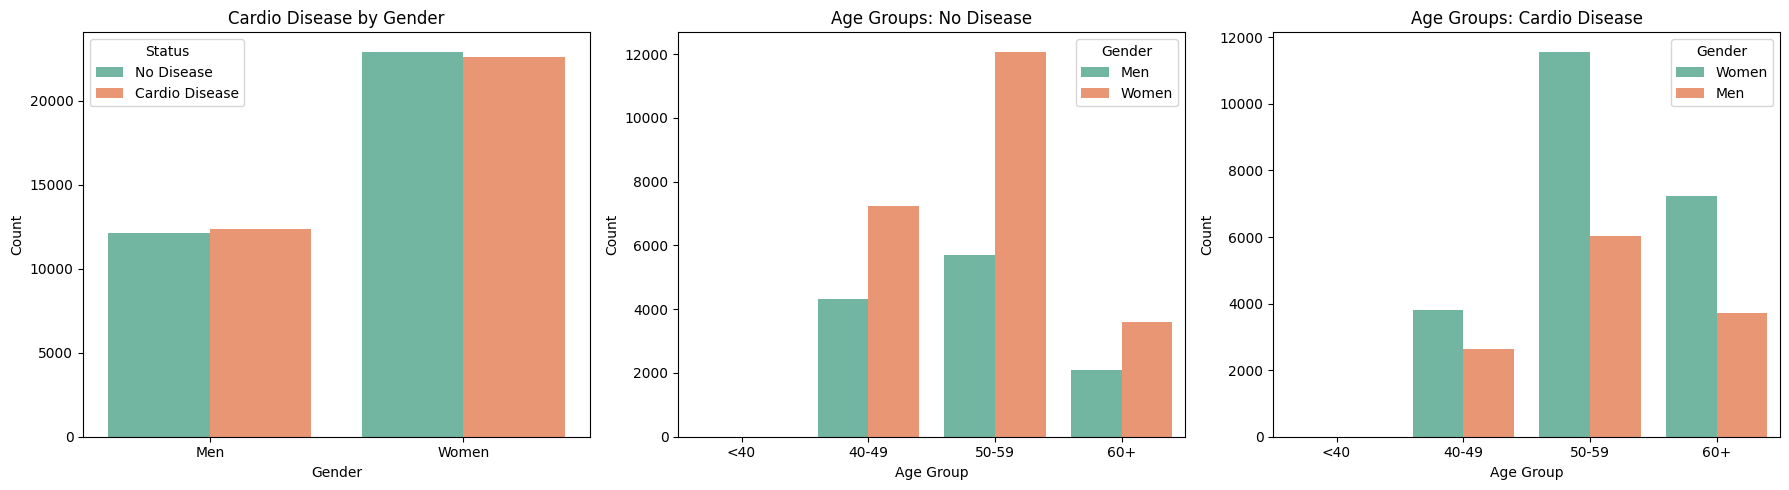

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), sharey=False)

sns.countplot(
    data=data, 
    x='gender_label', 
    hue='cardio_label', 
    palette='Set2', 
    ax=axes[0]
)
axes[0].set_title('Cardio Disease by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')
axes[0].legend(title='Status')

no_disease = data[data['cardio_label'] == 'No Disease']
has_disease = data[data['cardio_label'] == 'Cardio Disease']

sns.countplot(
    data=no_disease, 
    x='age_group', 
    hue='gender_label', 
    palette='Set2', 
    ax=axes[1]
)
axes[1].set_title('Age Groups: No Disease')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Count')
axes[1].legend(title='Gender')

sns.countplot(
    data=has_disease, 
    x='age_group', 
    hue='gender_label', 
    palette='Set2', 
    ax=axes[2]
)
axes[2].set_title('Age Groups: Cardio Disease')
axes[2].set_xlabel('Age Group')
axes[2].set_ylabel('Count')
axes[2].legend(title='Gender')

plt.tight_layout()
plt.show()

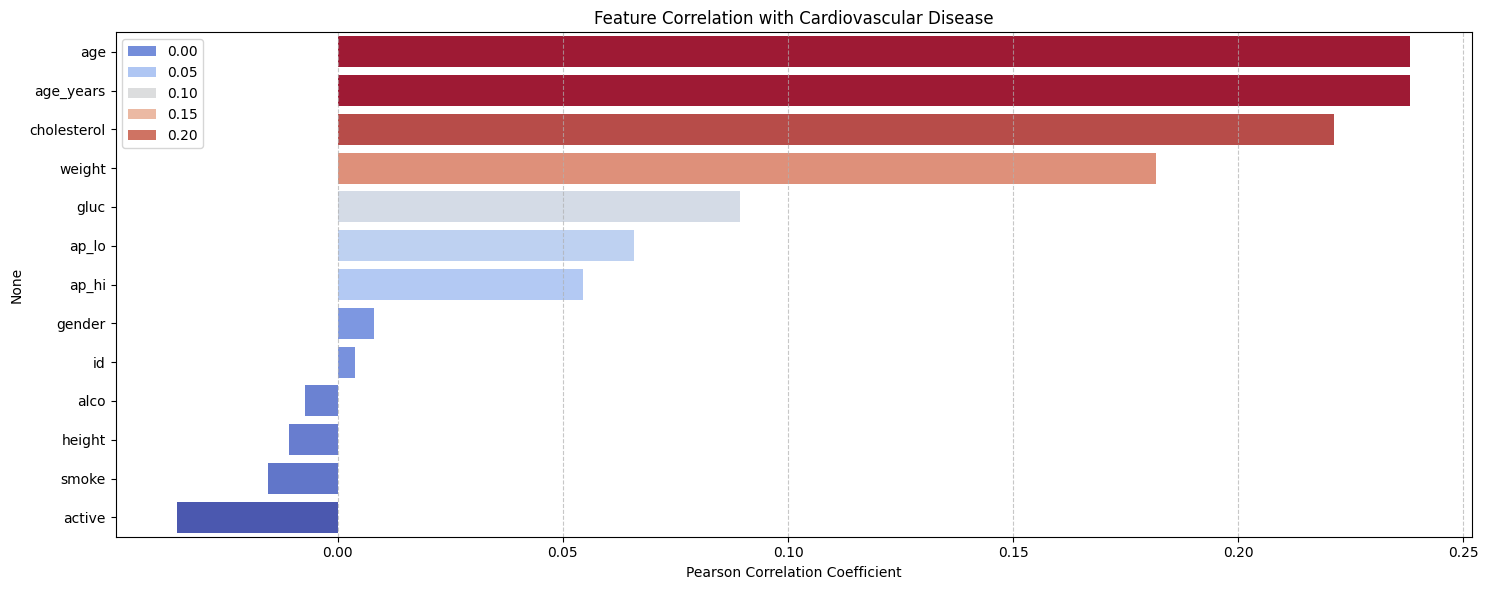

In [8]:
corr = data.corr(numeric_only=True)

target_corr = corr['cardio'].drop('cardio').sort_values(ascending=False)

plt.figure(figsize=(15, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.values, palette="coolwarm")
plt.title("Feature Correlation with Cardiovascular Disease")
plt.xlabel("Pearson Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [9]:
# examine the associations between clinical examination metrics and the presence of cardiovascular disease
# Logistic regression and odds ratio calculations are used to quantify how elevated clinical readings and abnormal biomarkers compound individual risk profiles.

import statsmodels.formula.api as smf

# We include cardio as the target, and your clinical metrics as predictors
formula = 'cardio ~ ap_hi + ap_lo + cholesterol + gluc + age_years'

# Fit the Generalized Linear Model (Logit)
logit_model = smf.logit(formula=formula, data=data).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.597074
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 cardio   No. Observations:                70000
Model:                          Logit   Df Residuals:                    69994
Method:                           MLE   Df Model:                            5
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                  0.1386
Time:                        09:24:03   Log-Likelihood:                -41795.
converged:                       True   LL-Null:                       -48520.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -8.8931      0.097    -91.799      0.000      -9.083      -8.703
ap_hi           0.0423    

In [10]:
params = logit_model.params
conf = logit_model.conf_int()

# Create a clean summary dataframe for Odds Ratios and 95% Confidence Intervals
or_df = pd.DataFrame({
    'Odds Ratio (OR)': np.exp(params),
    '2.5% CI': np.exp(conf[0]),
    '97.5% CI': np.exp(conf[1]),
    'p-value': logit_model.pvalues
})

print(or_df.sort_values(by='Odds Ratio (OR)', ascending=False))

             Odds Ratio (OR)   2.5% CI  97.5% CI        p-value
cholesterol         1.713409  1.664289  1.763979  2.847040e-288
age_years           1.055994  1.053341  1.058655   0.000000e+00
ap_hi               1.043259  1.042045  1.044474   0.000000e+00
ap_lo               1.000301  1.000167  1.000435   1.051355e-05
gluc                0.907969  0.878399  0.938535   1.096665e-08
Intercept           0.000137  0.000114  0.000166   0.000000e+00
